<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/homeworks/base/HW1_Regression_with_inference_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Домашнее задание №1 (base)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;

**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–4 (EDA, модели, категориальные признаки, бизнес-метрика) — 5 баллов;
- Часть 5, оформление репозитория — 2 балла;
- Часть 6, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
!pip install -q ydata-profiling  # numba в Colab пока не поддерживает NumPy 2.4

In [2]:
!pip install -q "setuptools<82"

In [3]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

/tmp/ipykernel_221751/1741596216.py:7: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

Для воспроизводимости решения

# **Часть 1 | EDA и визуализация**

Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.5 балла)
- Визуализации признаков и их анализ (1 балл)

Всего за эту часть можно набрать 2.5 балла.

## **Простейший EDA и обработка признаков (1.5 балла)**

In [4]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.45 балла)**

Вы уже встречались с pandas в первой половине семестра. Теперь будем постоянно (кроме некоторых случаев) использовать его для анализа данных и наслаивать навыки. Выполните операции, направленные на практику основных действий с `pandas`:

**0.1 балла**
- [ ] Отобразите 30 случайных строк тренировочного датасета.
- [ ] Отобразите первые 5 и последние 5 объектов тестового датасета
- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения
- [ ] Посмотрите, есть ли в данных явные дубликаты


**0.2 балла**
Ответьте на вопросы:
- [ ] О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?
- [ ] Достаточно ли метода duplicated для анализа дубликатов? Почему?

**0.15 балла**
- [ ] Постройте дашборд, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling)

#### Отобразите 30 случайных строк тренировочного датасета.

In [5]:
df_train.sample(n=30)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
6565,Renault KWID Climber 1.0 MT BSIV,2019,300000,35000,Petrol,Individual,Manual,First Owner,23.01 kmpl,999 CC,67 bhp,91Nm@ 4250rpm,5.0
2943,Maruti Wagon R LXI,2013,225000,58343,Petrol,Trustmark Dealer,Manual,First Owner,21.79 kmpl,998 CC,67.05 bhp,90Nm@ 3500rpm,5.0
2024,Hyundai i20 Asta 1.2,2013,360000,30000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
263,Hyundai i20 1.2 Asta,2010,300000,70000,Petrol,Individual,Manual,First Owner,17.0 kmpl,1197 CC,80 bhp,"11.4 kgm at 4,000 rpm",5.0
4586,Skoda Octavia L and K 1.9 TDI MT,2005,250000,120000,Diesel,Individual,Manual,Third Owner,16.4 kmpl,1896 CC,90 bhp,"21.4@ 1,900(kgm@ rpm)",5.0
4479,Maruti Ciaz ZXi,2016,700000,20000,Petrol,Individual,Manual,First Owner,20.73 kmpl,1373 CC,91.1 bhp,130Nm@ 4000rpm,5.0
4881,Hyundai Grand i10 1.2 Kappa Magna BSIV,2017,445000,27000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
3583,Ford Ecosport 1.5 DV5 MT Trend,2016,515000,68609,Diesel,Dealer,Manual,First Owner,22.7 kmpl,1498 CC,89.84 bhp,204Nm@ 2000-2750rpm,5.0
6361,Hyundai Verna 1.4 VTVT,2014,500000,33400,Petrol,Individual,Manual,First Owner,17.43 kmpl,1396 CC,105.5 bhp,135.3Nm@ 5000rpm,5.0
4108,Hyundai i20 Era 1.2,2015,490000,45900,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0


#### Отобразите первые 5 и последние 5 объектов тестового датасета

In [6]:
display(df_test.head())
display(df_test.tail())

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Mahindra Xylo E4 BS IV,2010,229999,168000,Diesel,Individual,Manual,First Owner,14.0 kmpl,2498 CC,112 bhp,260 Nm at 1800-2200 rpm,7.0
1,Tata Nexon 1.5 Revotorq XE,2017,665000,25000,Diesel,Individual,Manual,First Owner,21.5 kmpl,1497 CC,108.5 bhp,260Nm@ 1500-2750rpm,5.0
2,Honda Civic 1.8 S AT,2007,175000,218463,Petrol,Individual,Automatic,First Owner,12.9 kmpl,1799 CC,130 bhp,172Nm@ 4300rpm,5.0
3,Honda City i DTEC VX,2015,635000,173000,Diesel,Individual,Manual,First Owner,25.1 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0
4,Tata Indica Vista Aura 1.2 Safire BSIV,2011,130000,70000,Petrol,Individual,Manual,Second Owner,16.5 kmpl,1172 CC,65 bhp,96 Nm at 3000 rpm,5.0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
995,Hyundai i10 Magna 1.1L,2008,250000,100000,Petrol,Individual,Manual,Second Owner,19.81 kmpl,1086 CC,68.05 bhp,99.04Nm@ 4500rpm,5.0
996,Hyundai i20 2015-2017 Sportz 1.2,2017,440000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
997,Hyundai i20 Era Diesel,2009,340000,40000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
998,Hyundai i10 Asta,2012,350000,25000,Petrol,Individual,Manual,First Owner,20.36 kmpl,1197 CC,78.9 bhp,111.8Nm@ 4000rpm,5.0
999,Honda City i DTec SV,2016,700000,110000,Diesel,Individual,Manual,First Owner,26.0 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0


#### Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения

In [7]:
print(df_train.info())
print(df_test.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6999 entries, 0 to 6998
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6999 non-null   object 
 1   year           6999 non-null   int64  
 2   selling_price  6999 non-null   int64  
 3   km_driven      6999 non-null   int64  
 4   fuel           6999 non-null   object 
 5   seller_type    6999 non-null   object 
 6   transmission   6999 non-null   object 
 7   owner          6999 non-null   object 
 8   mileage        6797 non-null   object 
 9   engine         6797 non-null   object 
 10  max_power      6803 non-null   object 
 11  torque         6796 non-null   object 
 12  seats          6797 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 711.0+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------   

In [8]:
print(df_train.columns[df_train.isna().any()].tolist())
print(df_test.columns[df_test.isna().any()].tolist())

['mileage', 'engine', 'max_power', 'torque', 'seats']
['mileage', 'engine', 'max_power', 'torque', 'seats']


#### Посмотрите, есть ли в данных явные дубликаты

In [9]:
print(f'Дупликатов в train: {df_train.duplicated().sum()}') 
print(f'Дупликатов в test: {df_test.duplicated().sum()}') 

Дупликатов в train: 985
Дупликатов в test: 62


#### О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?

Ответ: О видых данных, отсортированны ли данные

#### Достаточно ли метода duplicated для анализа дубликатов? Почему?

Ответ: Не совсем, метод может упустить строки где могут быть например заные типы но по сути речь об одно и то же: 1 vs 1.0 vs "1", или разные записи одного и того же: Москва vs г. Москва vs москва

#### Постройте дашборд, используя ydata-profiling

In [10]:
profile = ProfileReport(
    df_train,
    title="Мой дашборд по данным",
    explorative=True  
)

profile.to_file("dashboard_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 13/13 [00:00<00:00, 87.82it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### **Задание 2 (0.5 балла)**

На прошлом шаге вы рассмотрели дубликаты. Однако дубликат может быть связан не только с полным повторением информации в нескольких строках, но и частичным. Например, объект мог быть внесён в базу данных с разным значением целевой переменной. В этом шаге займемся такими дублями!

**Ваши действия:**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.1 балла)
- [ ] Отобразите такие объекты (0.15 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.15 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.1 балла)


#### Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.1 балла)


In [11]:
features = df_train.columns.drop('selling_price')
print(df_train.duplicated(subset=features).sum())

1159


####  Отобразите такие объекты (0.15 балла)

In [12]:
dup_mask = df_train.duplicated(subset=features, keep=False)
dups = df_train[dup_mask].sort_values(by=list(features))
dups

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1703,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
6307,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
1836,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
6704,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
117,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5637,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5652,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5753,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5991,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0


#### Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.15 балла)

In [13]:
df_train = df_train.drop_duplicates(subset=features, keep="first")

#### Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.1 балла)

In [14]:
df_train = df_train.reset_index(drop=True)

In [15]:
assert df_train.shape == (5840, 13)

Отлично! Мы избавились от маленьких и явных проблем. Теперь перейдем к более сложным недостаткам полученной таблицы.

### **Задание 3 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Удалите столбец ``torque``


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.
- Столбец ``torque`` мы удаляем для простоты. В идеальном случае, его также стоило бы предобработать.

In [16]:
def clean_numeric_column(series: pd.Series) -> pd.Series:
    """Убирает всё, кроме числа (и точки), приводит к float."""
    return (
        series.astype(str)
              .str.extract(r'([\d.]+)')  
              .astype(float)
    )

def preprocess(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for col in ['mileage', 'engine', 'max_power']:
        df[col] = clean_numeric_column(df[col])
    df = df.drop(columns=['torque'])
    return df

df_train = preprocess(df_train)
df_test = preprocess(df_test)
df_train.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0
3,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0
4,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14,1197.0,81.86,5.0


### **Задание 4 (0.15 балла)**

В Задании 1 мы обнаружили пропуски. Давайте избавимся от них.

**Шаг 1 (0.05 балла)**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось. Заполнение пропусков проводите для обоих наборов данных, если необходимо

**Важно!**

При заполнении пропусков и в тестовом, и тренировочном наборах данных вы определяетесь со стратегией предобработки пропущенных значений при потенциальной работе модели.

Так как в теоретическом случае вы не имеете доступа к тестовой выборке, то заполняемое значение (у нас — медиана) вы считаете по *тренировочному* набору данных и им же заполняете *тестовый*.

In [17]:
medians = df_train.median(numeric_only=True)
df_train = df_train.fillna(medians)
df_test = df_test.fillna(medians)
print(medians)
print(df_train.isna().sum())
print(df_test.isna().sum())

year               2014.00
selling_price    405000.00
km_driven         70000.00
mileage              19.37
engine             1248.00
max_power            81.86
seats                 5.00
dtype: float64
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
dtype: int64
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
dtype: int64


**Шаг 2 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.

In [18]:
df_train[['engine', 'seats']] = df_train[['engine', 'seats']].astype(int)
df_test[['engine', 'seats']] = df_test[['engine', 'seats']].astype(int)
print(df_train[['engine', 'seats']].dtypes)
print(df_test[['engine', 'seats']].dtypes)

engine    int64
seats     int64
dtype: object
engine    int64
seats     int64
dtype: object


### **Задание 5 (0.15 балла)**

Отлично! Мы провели "косметическую" предобработку и теперь готовы сделать важный шаг в контексте анализа данных. А именно — посмотреть на статистики!

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сделайте вывод.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

**Примечание:**

Более корректно рассматривать статистики до заполнения пропусков и после, чтобы убедиться, что мы не внесли каких-либо серьезных сдвигов в изначальные распределения.

####  Посчитайте основные статистики по числовым столбцам для трейна и теста

In [19]:
num_stats_train = df_train.describe(include='number').T
num_stats_test  = df_test.describe(include='number').T

display(num_stats_train)
display(num_stats_test)

,count,mean,std,min,25%,50%,75%,max
year,5840.0,2013.428425,4.095622,1983.0,2011.00,2014.00,2017.0,2020.0
selling_price,5840.0,522960.091096,535432.001912,29999.0,250000.00,405000.00,640000.0,10000000.0
km_driven,5840.0,73952.242466,60071.136504,1.0,39000.00,70000.00,100000.0,2360457.0
mileage,5840.0,19.430841,3.985973,0.0,16.95,19.37,22.3,42.0
engine,5840.0,1429.448973,485.662834,624.0,1197.00,1248.00,1498.0,3604.0
max_power,5840.0,87.906371,31.640418,0.0,68.00,81.86,99.0,400.0
seats,5840.0,5.426712,0.982344,2.0,5.00,5.00,5.0,14.0


,count,mean,std,min,25%,50%,75%,max
year,1000.0,2013.68100,4.012149,1995.0,2011.00,2014.000,2017.0,2020.00
selling_price,1000.0,617901.04200,758553.860710,31000.0,250000.00,434999.000,670000.0,6000000.00
km_driven,1000.0,71393.34100,48486.218662,1303.0,37000.00,61500.000,100000.0,375000.00
mileage,1000.0,19.33881,3.951750,0.0,16.55,19.370,22.3,32.26
engine,1000.0,1454.87600,521.995740,624.0,1197.00,1248.000,1582.0,3604.00
max_power,1000.0,90.84167,34.893389,34.2,69.00,82.425,102.0,280.00
seats,1000.0,5.40300,0.912921,4.0,5.00,5.000,5.0,9.00


#### Посчитайте основные статистики по категориальным столбцам для трейна и теста

In [20]:
cat_stats_train = df_train.describe(include='object').T
cat_stats_test  = df_test.describe(include='object').T

display(cat_stats_train)
display(cat_stats_test)

,count,unique,top,freq
name,5840,1924,Maruti Swift Dzire VDI,91
fuel,5840,4,Diesel,3177
seller_type,5840,3,Individual,5223
transmission,5840,2,Manual,5336
owner,5840,5,First Owner,3603


,count,unique,top,freq
name,1000,621,Maruti Alto 800 LXI,15
fuel,1000,4,Diesel,534
seller_type,1000,3,Individual,837
transmission,1000,2,Manual,877
owner,1000,5,First Owner,623


#### Статитстики исходных датасетов без обработки

In [21]:
df_train_origin = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test_origin = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

num_stats_train_origin = df_train_origin.describe(include='number').T
num_stats_test_origin  = df_test_origin.describe(include='number').T

display(num_stats_train_origin)
display(num_stats_test_origin)

,count,mean,std,min,25%,50%,75%,max
year,6999.0,2013.818403,4.053095,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,6999.0,639515.197171,808941.911915,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,6999.0,69584.615517,57724.001817,1.0,35000.0,60000.0,97000.0,2360457.0
seats,6797.0,5.419008,0.965767,2.0,5.0,5.0,5.0,14.0


,count,mean,std,min,25%,50%,75%,max
year,1000.0,2013.681000,4.012149,1995.0,2011.0,2014.0,2017.0,2020.0
selling_price,1000.0,617901.042000,758553.860710,31000.0,250000.0,434999.0,670000.0,6000000.0
km_driven,1000.0,71393.341000,48486.218662,1303.0,37000.0,61500.0,100000.0,375000.0
seats,981.0,5.410805,0.919985,4.0,5.0,5.0,5.0,9.0


In [22]:
cat_stats_train_origin = df_train_origin.describe(include='object').T
cat_stats_test_origin  = df_test_origin.describe(include='object').T

display(cat_stats_train_origin)
display(cat_stats_test_origin)

,count,unique,top,freq
name,6999,1924,Maruti Swift Dzire VDI,116
fuel,6999,4,Diesel,3793
seller_type,6999,3,Individual,5826
transmission,6999,2,Manual,6095
owner,6999,5,First Owner,4587
mileage,6797,386,18.9 kmpl,197
engine,6797,120,1248 CC,885
max_power,6803,316,74 bhp,330
torque,6796,419,190Nm@ 2000rpm,468


,count,unique,top,freq
name,1000,621,Maruti Alto 800 LXI,15
fuel,1000,4,Diesel,534
seller_type,1000,3,Individual,837
transmission,1000,2,Manual,877
owner,1000,5,First Owner,623
mileage,981,237,18.6 kmpl,23
engine,981,88,1248 CC,116
max_power,981,182,74 bhp,43
torque,981,226,200Nm@ 1750rpm,57


#### Сделайте вывод.
- Числовые признаки имеют разные масштабы
- у mileage, engine, max_power, price максимум заметно выше 75-го перцентиля, значит есть длинный правый хвост
- У столбца name 1924 уникальных объектов, если использовать OHE это приведет к разреженности матрицы признаков.
- У категориальных столбцов сильный дисбаланс классов
- После обработки распределение численных признаков сильно не поменялось (единственное, увеличилось кол-во числовых признаков после обработки столбцов mileage и т. д.)

Лучше отмасштабировать числовые признаки и удалить признак name (для OHE) или использовать Target Encoding

In [23]:
# torque удалён в Задании 3, поэтому столбцов 12
assert df_train.shape == (5840, 12)

## **Визуализации (1 балл)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 6 (0.4 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

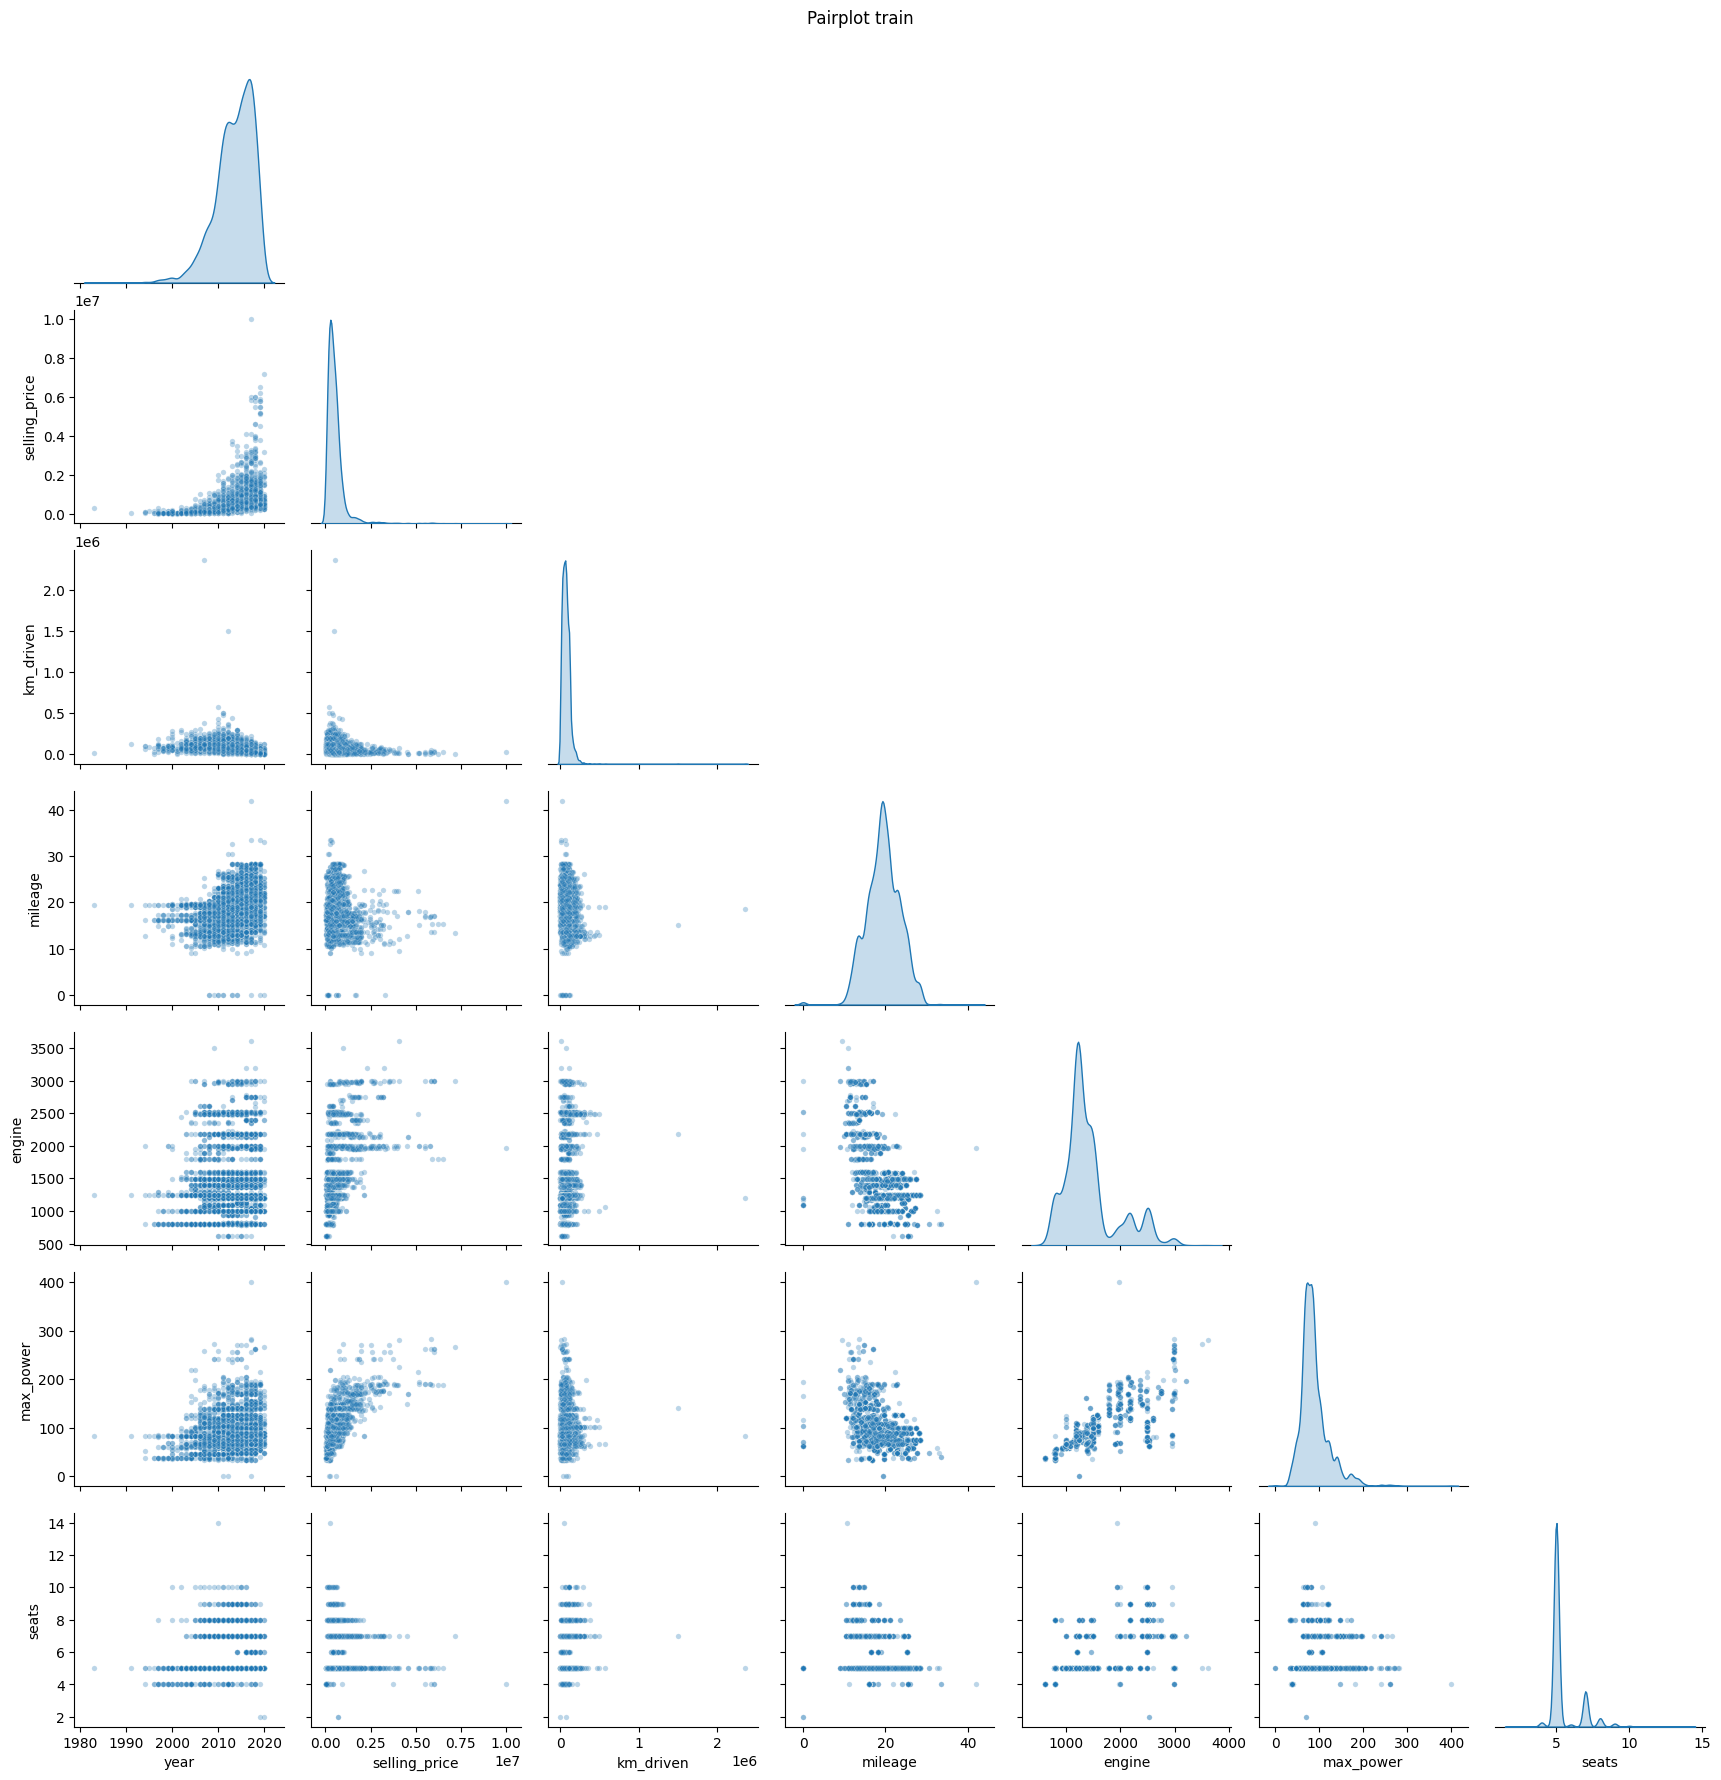

In [24]:
num_cols = ['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

sns.pairplot(
    df_train[num_cols],
    diag_kind='kde',       
    corner=True,            
    plot_kws={'alpha': 0.3, 's': 15}
)
plt.suptitle("Pairplot train", y=1.02)
plt.show()

#### По полученному графику ответьте на вопросы:
Можно ли предположить на основе распределений связь признаков с целевой переменной?

Ответ: Можно, например видна зависимость цены от максимальной мощности: чем больше мощность тем больше облако точек смещается вправо

Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Ответ: Можно, например видна корреляция между максимальной мощностью и двигателем, чем больше двигатель тем больше максимальная мощность

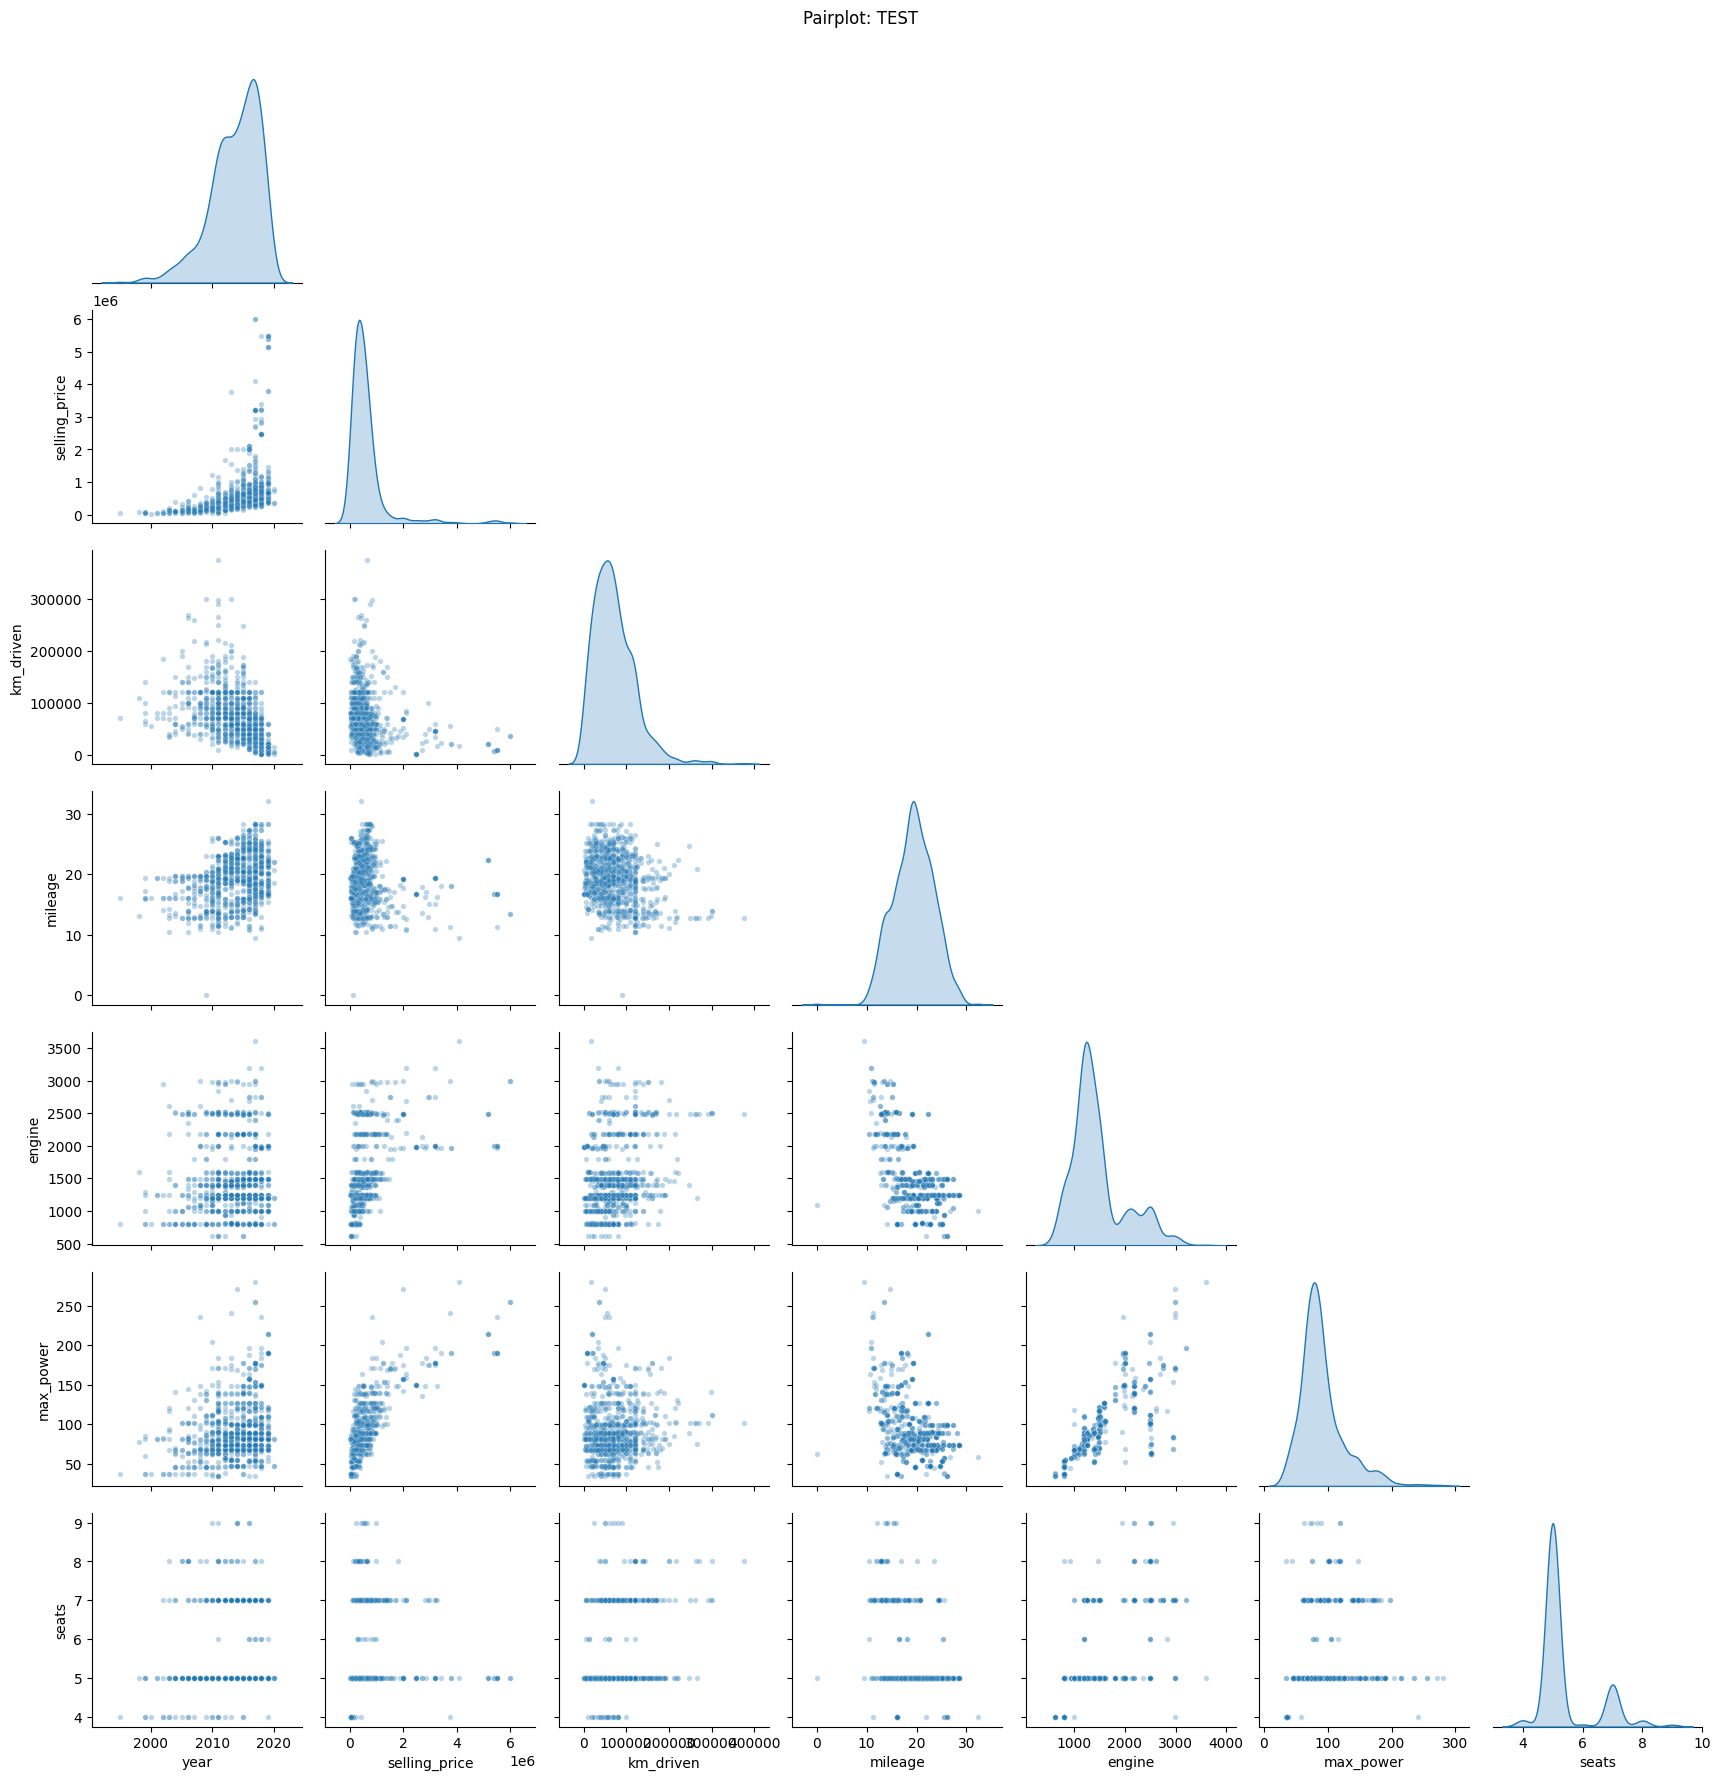

In [25]:
sns.pairplot(
    df_test[num_cols],          
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.3, 's': 15}
)
plt.suptitle("Pairplot: TEST", y=1.02)
plt.show()

#### Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

Ответ: Визуально распределения по форме похожи, но некоторые облака точек на train более сплющенные и плотные чем в test хотя форма похожа. Скорее всего плотность обучловлена размерами выборки а рспределение на train репрезентативно для test

### **Задание 7 (0.35 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

In [26]:
num_cols = ['selling_price', 'year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
corr_matrix = df_train[num_cols].corr(method='pearson')
corr_matrix.round(2)

,selling_price,year,km_driven,mileage,engine,max_power,seats
selling_price,1.00,0.43,-0.16,-0.10,0.45,0.69,0.15
year,0.43,1.00,-0.37,0.34,0.00,0.16,0.04
km_driven,-0.16,-0.37,1.00,-0.18,0.23,0.02,0.19
mileage,-0.10,0.34,-0.18,1.00,-0.57,-0.37,-0.45
engine,0.45,0.00,0.23,-0.57,1.00,0.68,0.65
max_power,0.69,0.16,0.02,-0.37,0.68,1.00,0.24
seats,0.15,0.04,0.19,-0.45,0.65,0.24,1.00


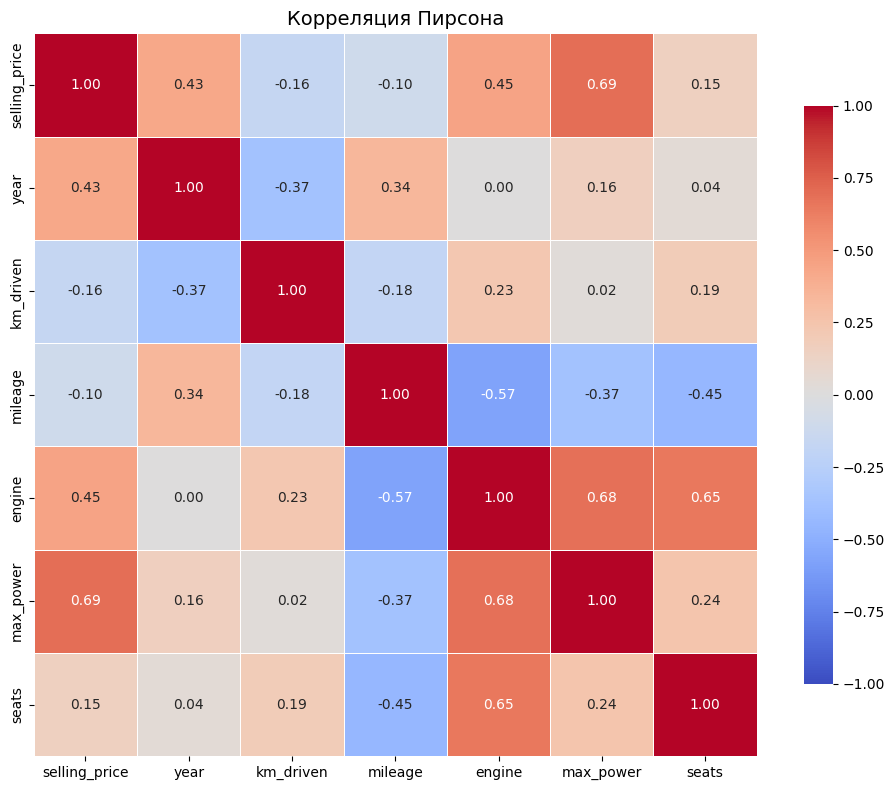

In [27]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,        
    fmt='.2f',           
    cmap='coolwarm',    
    center=0,            
    vmin=-1, vmax=1,    
    square=True,         
    linewidths=0.5,      
    cbar_kws={'shrink': 0.8}
)

plt.title('Корреляция Пирсона', fontsize=14)
plt.tight_layout()
plt.show()

- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?

- Наименне скоррелированы признаки year и engine: 0.0 линейной связи вообще нет
- Довольно сильная положительная связь у признаков max_power и engine: 0.68
- Да, так как корреляция отрицательная: чем больше year (чем новее машина) тем меньше km_driven (меньше пробег) и наоборот

### **Задание 8 (0.25 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

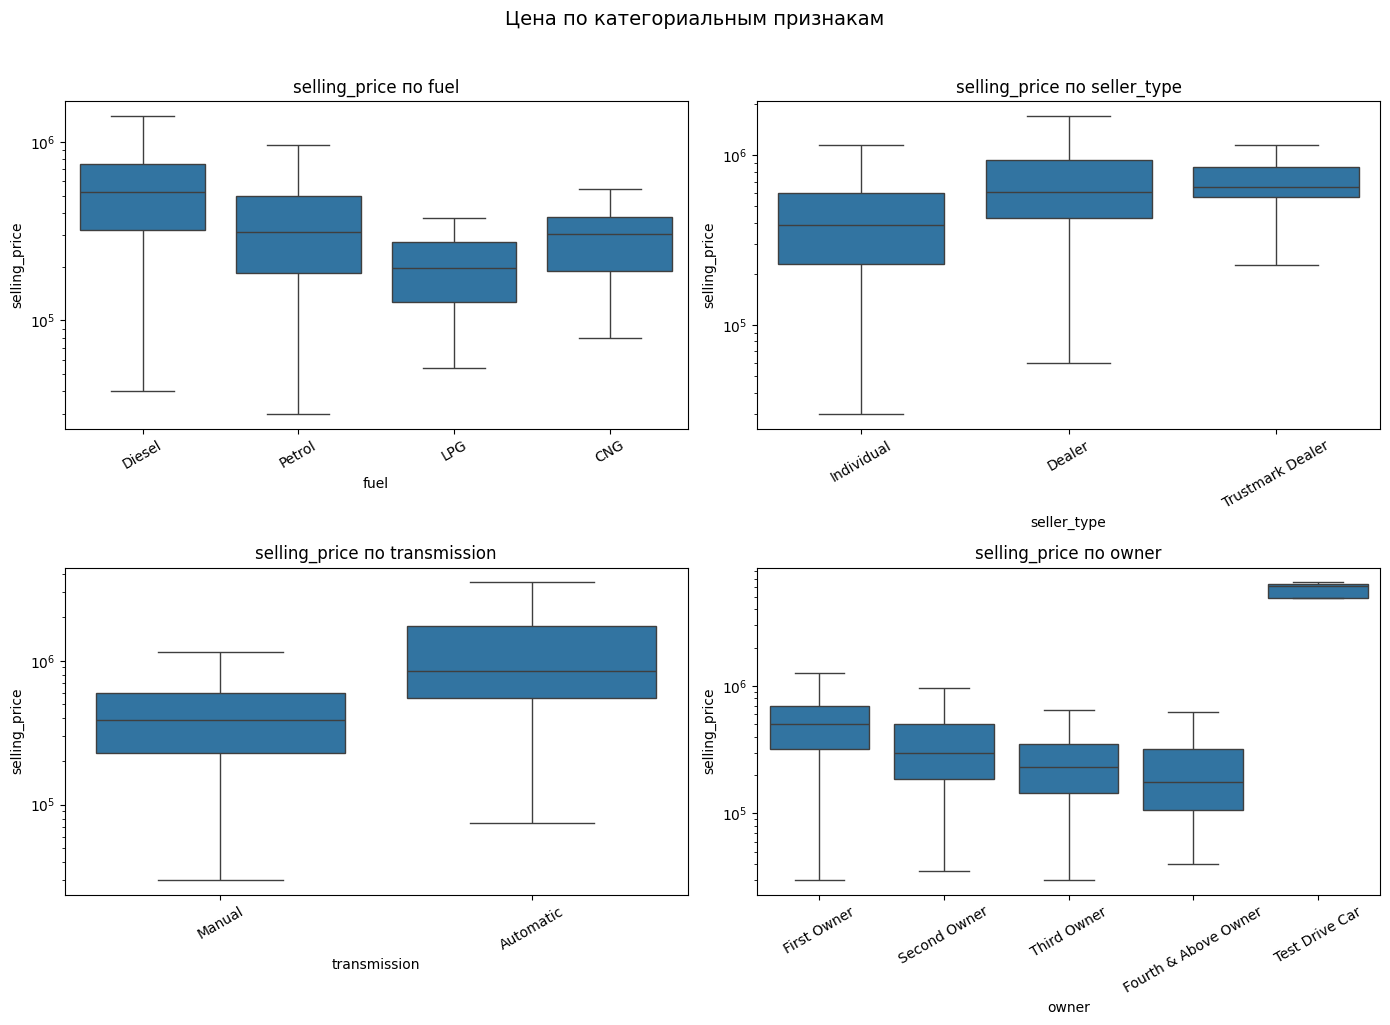

In [28]:
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner']  
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.ravel(), cat_cols):
    sns.boxplot(
        data=df_train, x=col, y='selling_price',
        ax=ax, showfliers=False      
    )
    ax.set_yscale('log')
    ax.set_title(f'selling_price по {col}')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Цена по категориальным признакам', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Пояснение: Мы не посмотрели на зависимость таргета от категориальных признаков. Это важно так как эти признаки тоже могут нести в себе сильные сигналы для модели, которве не видны на корреляционной матрице.

по графикам видно:
- Зависимость цены от типа топлива: к примеру машины на дизеле в среднем дороже, но при этом сильный разброс ценн (так как в датасете эта категория преобладает)
- У индивидуальных продавцов (не диллеров) купить машину дешевле
- Машины на автоматике дороже чем на мехнике
- Четкая зваисимость что чем больше было владельцем тем меньше цена + какие-то выбро у тестовых машин (может быть специально, по типу что такие машины не продаются)

# **Часть 2 | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.25 балла.

### **Задание 9 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test при разбиении. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [29]:
num_features = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
df_train_num = df_train[num_features + ['selling_price']].copy()
df_test_num  = df_test[num_features+ ['selling_price']].copy()   

y_train = df_train_num['selling_price']
X_train = df_train_num[num_features]

In [30]:
# опишите выбранные вещественные признаки

In [31]:
y_test = df_test_num['selling_price']
X_test = df_test_num[num_features]

### **Задание 10 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [32]:
model = LinearRegression()
model.fit(X_train, y_train)
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

def print_metrics(y_true, y_pred, name):
    mse = MSE(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name}: MSE = {mse:.0f}   R2 = {r2:.4f}")

print_metrics(y_train, y_train_pred, "TRAIN")
print_metrics(y_test, y_test_pred, "TEST")

TRAIN: MSE = 116874153930   R2 = 0.5923
TEST: MSE = 233298779730   R2 = 0.5941


Выводы: 
- Переобучения у модели нет R2 примерно одинаковый
- Огромный разрыв MSE скорее всего связан с тем что данные не отмасштабированы или из-за наличия выбросов или длинного хвоста в цене

### **Задание 11 (0.15 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [33]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=X_test.columns,  index=X_test.index)

model_scaled = LinearRegression().fit(X_train_scaled, y_train)
y_train_pred_scaled = model_scaled.predict(X_train_scaled)
y_test_pred_scaled = model_scaled.predict(X_test_scaled)

print_metrics(y_train, y_train_pred_scaled, "TRAIN")
print_metrics(y_test, y_test_pred_scaled, "TEST")

TRAIN: MSE = 116874153930   R2 = 0.5923
TEST: MSE = 233298779730   R2 = 0.5941


### **Задание 12 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

In [34]:
coefs = pd.Series(model_scaled.coef_, index=X_train.columns)
coefs_abs = coefs.abs().sort_values(ascending=False)
coefs_abs

max_power    322807.353259
year         152772.570846
engine        61178.494337
km_driven     44158.818520
mileage       28833.925778
seats         23209.132486
dtype: float64

Наиболее информативен max_power

### **Задание 13 (0.25 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [35]:
lasso = Lasso()                    
lasso.fit(X_train_scaled, y_train)

y_train_pred_lasso = lasso.predict(X_train_scaled)
y_test_pred_lasso  = lasso.predict(X_test_scaled)

print_metrics(y_train, y_train_pred_lasso, "TRAIN")
print_metrics(y_test, y_test_pred_lasso, "TEST")

TRAIN: MSE = 116874153940   R2 = 0.5923
TEST: MSE = 233299450599   R2 = 0.5941


In [36]:
coefs_lasso = pd.Series(lasso.coef_, index=X_train.columns)
coefs_lasso

year         152772.390214
km_driven    -44157.689858
mileage       28832.043396
engine        61173.662409
max_power    322808.236919
seats        -23206.255649
dtype: float64

Лассо не занулила веса, из-за того что штраф слишком слаб (alpha=1.0)

### **Задание 14 Финальный рывок (0.5 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [37]:
param_grid = {'alpha': [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]}   

cv = KFold(n_splits=10, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=Lasso(max_iter=100_000),
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1,
    return_train_score=True
)
grid_search.fit(X_train_scaled, y_train)

y_train_pred_gs = grid_search.predict(X_train_scaled)
y_test_pred_gs  = grid_search.predict(X_test_scaled)

print_metrics(y_train, y_train_pred_gs, "TRAIN")
print_metrics(y_test, y_test_pred_gs, "TEST")

TRAIN: MSE = 116884005961   R2 = 0.5922
TEST: MSE = 233977618531   R2 = 0.5930


#### Сколько грид-сёрчу пришлось обучать моделей?

9 - кол-во вариантов гиперпараметра aplha

In [38]:
len(grid_search.cv_results_['params'])

9

#### Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [39]:
print(grid_search.best_estimator_)
pd.Series(grid_search.best_estimator_.coef_, index=X_train.columns)

Lasso(alpha=1000.0, max_iter=100000)


year         152556.386616
km_driven    -43052.234680
mileage       27010.694999
engine        56435.714938
max_power    323666.834812
seats        -20352.142469
dtype: float64

Лучший aplha=1000, веса не занулились

**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [40]:
param_grid_en = {
    'alpha':    [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0],      
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9], 
}

cv = KFold(n_splits=10, shuffle=True, random_state=42)

grid_en = GridSearchCV(
    estimator=ElasticNet(max_iter=100_000),
    param_grid=param_grid_en,
    cv=cv,
    scoring='r2',
    n_jobs=-1,
    return_train_score=True
)
grid_en.fit(X_train_scaled, y_train)

y_train_pred_en = grid_en.predict(X_train_scaled)
y_test_pred_en = grid_en.predict(X_test_scaled)

print_metrics(y_train, y_train_pred_en, "TRAIN")
print_metrics(y_test, y_test_pred_en, "TEST")

TRAIN: MSE = 117201854417   R2 = 0.5911
TEST: MSE = 239624197052   R2 = 0.5831


#### Сколько грид-сёрчу пришлось обучать моделей?

In [41]:
len(grid_en.cv_results_['params'])

45

#### Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [42]:
grid_en.best_estimator_

,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",0.1
,"max_iter max_iter: int, default=1000The maximum number of iterations.",100000
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet<sphx_glr_auto_examples_linear_model_plot_elastic_net_precomputed_gram_matrix_with_weighted_samples.py>`for details.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


aplha=0.1
l1_ratio=0.5

# **Часть 3 | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.75 балла.

**Задание 15 (0.1 балла)** Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

В этом домашнем задании мы предлагаем удалить его.

**Ваша задача:**
- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Удалите из них столбец `name`

In [43]:
X_train_cat = df_train.drop(columns=['selling_price']).copy()
X_test_cat  = df_test.drop(columns=['selling_price']).copy()          

X_train_cat = X_train_cat.drop(columns=['name'])
X_test_cat  = X_test_cat.drop(columns=['name'])

В другом случае, конечно, мы могли бы предобработать данный столбец (например, выделить из названия марку автомобиля). В этом задании этого делать не нужно.

In [44]:
assert X_train_cat.shape == (5840, 10)

In [45]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3177,5223,5336,3603


### **Задание 16 (0.4 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования. Обратите внимание, что во избежание мультиколлинеарности следует избавиться от одного из полученных столбцов при кодировании каждого признака методом OneHot.

In [46]:
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']

X_train_ohe = pd.get_dummies(
    X_train_cat,
    columns=cat_cols,
    drop_first=True,
    dtype=float
)
X_test_ohe = pd.get_dummies(
    X_test_cat,
    columns=cat_cols,
    drop_first=True,
    dtype=float
)
X_test_ohe = X_test_ohe.reindex(columns=X_train_ohe.columns, fill_value=0)

### **Задание 17 (0.25 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [47]:
param_grid_ridge = {
    'alpha':    [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0],      
}

cv = KFold(n_splits=10, shuffle=True, random_state=42)

grid_ridge = GridSearchCV(
    estimator=Ridge(max_iter=100_000),
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='r2',           
    n_jobs=-1,
    return_train_score=True
)
grid_ridge.fit(X_train_ohe, y_train)

y_train_pred_r = grid_ridge.predict(X_train_ohe)
y_test_pred_r = grid_ridge.predict(X_test_ohe)

print_metrics(y_train, y_train_pred_r, "TRAIN")
print_metrics(y_test, y_test_pred_r, "TEST")

/home/elisei/Рабочий стол/year_project/EDA/ds_ml_env/lib/python3.12/site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=5.13593e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/home/elisei/Рабочий стол/year_project/EDA/ds_ml_env/lib/python3.12/site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=5.13593e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


TRAIN: MSE = 95368540024   R2 = 0.6673
TEST: MSE = 215970159251   R2 = 0.6243


Качество прогнозов удалось улучшить, что видно по метрике R2 она стала больше чем в предыдущих экспериментах

# **Часть 4 | Бизнесовая (0.5 балла)**

### **Задание 18 (0.5 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metric}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metric`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [48]:
def business_metric(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    relative_error = np.abs((y_pred - y_true) / y_true)
    return np.mean(relative_error <= 0.1)

print("LinearRegression")
print("TRAIN:", business_metric(y_train, y_train_pred))
print("TEST: ", business_metric(y_test, y_test_pred))

print("LinearRegression (scaled)")
print("TRAIN:", business_metric(y_train, y_train_pred_scaled))
print("TEST: ", business_metric(y_test, y_test_pred_scaled))

print("Lasso (best alpha)")
print("TRAIN:", business_metric(y_train, y_train_pred_lasso))
print("TEST: ", business_metric(y_test, y_test_pred_lasso))

print("ElasticNet (best params)")
print("TRAIN:", business_metric(y_train, y_train_pred_en))
print("TEST: ", business_metric(y_test, y_test_pred_en))

print("Ridge + OHE (best alpha)")
print("TRAIN:", business_metric(y_train, y_train_pred_r))
print("TEST: ", business_metric(y_test, y_test_pred_r))

LinearRegression
TRAIN: 0.21523972602739727
TEST:  0.227
LinearRegression (scaled)
TRAIN: 0.21523972602739727
TEST:  0.227
Lasso (best alpha)
TRAIN: 0.21523972602739727
TEST:  0.227
ElasticNet (best params)
TRAIN: 0.2190068493150685
TEST:  0.226
Ridge + OHE (best alpha)
TRAIN: 0.21575342465753425
TEST:  0.248


Лучше всего последняя модель Ridge

# **Часть 5 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import pickle

num_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power']
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore',
                              sparse_output=False), cat_cols),
    ],
    remainder='drop'
)

best_alpha = grid_ridge.best_params_['alpha']  

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=best_alpha, max_iter=100_000)),
])

final_pipeline.fit(X_train_cat, y_train)   

with open('ridge.pickle', 'wb') as f:
    pickle.dump(final_pipeline, f)

# **<font color="green">Часть 6 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 5 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 5 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.